## Contents
 
1. **[1. Set up](#sec-1)** — helper functions
   - [1.1 Euclidean distance squared](#sec-1-1)
   - [1.2 Factorizing matrices](#sec-1-2)
   - [1.3 Metrics](#sec-1-3)
   - [1.4 Coefficients used in objectives and constraints](#sec-1-4)
   - [1.5 Vectors and Matrices](#sec-1-5)
2. **[Import data](#sec-2)**
   - [2.1 Artificially generated problem](#sec-2-1)
   - [2.2 Randomly generated problems](#sec-2-2)
   - [2.3 Problems from real protein data](#sec-2-3)
   - [2.4 Check connectedness](#sec-2-4)
3. **[Algorithm](#sec-3)**
   - [3.1 Phase 1](#sec-3-1)
   - [3.2 Phase 2](#sec-3-2)
   - [3.3 Phase 3](#sec-3-3)
4. **[Simulations](#sec-4)**
   - [4.1 Artificially generated problem](#sec-4-1)
   - [4.2 Randomly generated problem](#sec-4-2)
   - [4.3 Real protein examples](#sec-4-3)
5. **[Augmented Lagrangian method](#sec-5)**
   - [5.1 Augmented lagrangian method](#sec-5-1)
   - [5.2 Memory comparison](#sec-5-2)


In [1]:
import cvxpy as cp
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import statistics,itertools,math,timeit,mosek,numba,gc,scipy.sparse

In [2]:
import os,threading,psutil,time # used when recording the memory used

In [3]:
from functools import reduce

In [4]:
from scipy import linalg
from scipy.sparse.linalg import eigsh
from scipy.linalg import block_diag
from scipy.sparse import csr_array
from prody import parsePDB, buildDistMatrix

In [5]:
from scipy import optimize as opt

In [6]:
np.random.seed(42)

In [7]:
SOLVER = cp.MOSEK #the solver we use. Note that it requires license

<a id="sec-1" name="sec-1"></a>
# 1. Set up

In this section, we write some functions that will be used later.

<a id="sec-1-1" name="sec-1-1"></a>
### 1.1 Euclidean distance squared
$\bullet$ my_dist(x,y) is a function that calculates $\|x-y \|_2^2$ for $x,y \in \mathbb{R}^n$. 

In [8]:
#x,y are tuples 
def my_dist(x,y): 
    norm2 = np.linalg.norm(np.subtract(x,y))
    return norm2*norm2

<a id="sec-1-2" name="sec-1-2"></a>
### 1.2 Factorizing matrices 
#### $\bullet $Rank 3 approximation

Let $X\in \mathbb{R}^{n\times n}$ be a real symmetric positive semidefinite matrix. We need to find $\widehat{V} \in \mathbb{R}^{n \times 3}$ such that $\| \widehat{V}\widehat{V}^T -X \|_F$ is minimized. This can be done by using eigenvalue decomposition, i.e., take $i$-th column of $\widehat{V}$ be $\sqrt{\lambda_i}p_i$ for $i = 1,2,3$, where $\lambda_i$ is the $i$-th largest eigenvalue and $p_i$ is the associated eigenvector.  

In [9]:
#Rank r approximation for X, where X is a real symmetric positive semidefinite
def rankkapprox(X,r):  
    eigenvalues, eigenvectors = eigsh(X,k = r, which = 'LM',return_eigenvectors=True)
    #eigsh sorts the eigenvalues in largest magnitude. 
    arra = np.zeros((r,len(X)))
    for i in range(r):
        arra[i] = math.sqrt(eigenvalues[i]) * eigenvectors[:, i]
    return arra.T
    

#### $\bullet$ Cholesky decomposition for symmetric positive semidefinite matrix 
Let $A \in \mathcal{S}^n$ and $A \succeq 0$. We want to find $H \in \mathbb{R}^{n\times n}$ such that $A = HH^T$.
<br>
As Python only has built-in Cholesky decomposition for positive definite matrix, we need to write our own function for positive semidefinite matrix. We use the function from 
 https://stackoverflow.com/questions/77818854/cholesky-decomposition-of-a-positive-semidefinite-matrix-using-some-python-libra.


In [10]:
def cholesky_for_semidefinite(A):
    L, piv, rank, info = linalg.lapack.dpstrf(A, lower=1)
    P = np.zeros((len(A),len(A))) #finds the unique L such that P^TAP = LL^T = A where P is a permutation matrix
    P[piv-1, np.arange(len(A))] = 1    
    L = np.tril(L) 
    L[:, rank:] = 0
    return P@L    #The inverse of a permutation matrix is its transpose. 
    

In [11]:
#test the function indeed return H such that HH^T = A.
for i in range(100):
    n = 10
    A = np.random.rand(n, n)
    A = A @ A.T
    L = cholesky_for_semidefinite(A)
    np.testing.assert_allclose(A, L @ L.T)

<a id="sec-1-3" name="sec-1-3"></a>
### 1.3 Metrics

#### $\bullet$ Error function
Let $V \in \mathbb{R}^{n \times 3}$  such that each row $v_i$ is the coordinate of $i$-th atom in computational results. Let $\delta_{ij}$ be the actual distance between atom $i$ and atom $j$. We want to minimize 
$$L(V) = \sum_{\{i,j\} \in E}  \mid \| v_i - v_j \|^2  - \delta_{ij}^2 \mid.$$

In [12]:
def error_LV(V,E,delta):
    L = 0
    
    for k,(i,j) in enumerate(E):
        L += abs(my_dist(V[i-1],V[j-1]) - delta[k])
        
    return L    

#### $\bullet$ Maximum amount of rational violations

The metric we used in artificially generared problem is $$L_{\max}(V) = \max_{\{i,j\} \in E}{\frac{ | \|v_i -v_j \| -\delta_{ij}|}{\delta_{ij}} \ }.$$

In [13]:
def max_violations(E,X,delta):
    violations = []
    for k, (i,j) in enumerate(E):
        delta_non_squared = math.sqrt(delta[k])
        violations.append(abs(np.linalg.norm(np.subtract(X[i-1],X[j-1])) - delta_non_squared) / delta_non_squared)
    
    return max(violations)    

<a id="sec-1-4" name="sec-1-4"></a>
### 1.4 Coefficients used in defining objectives and constraints

#### $\bullet$ Laplacian matrix of a graph given a set of edges  <br>

Let $G = (V,E)$ be a graph with $|V| = n$. Function laplacian(E,n) returns the laplacian matrix $L$ of $G$, i.e., 
$$ L = D - A$$
where $D$ is the degree matrix of $G$ and $A$ is the adjacency matrix of $G$.

In [14]:
def laplacian(E,n):
    
    row_ind,col_ind = [],[]
    data = [1,1,-1,-1] * len(E)
    
    for i,j in E: 
        row_ind += [i-1,j-1,i-1,j-1]
        col_ind += [i-1,j-1,j-1,i-1]
    
    return csr_array((data,(row_ind,col_ind)),dtype = np.int8, shape = (n,n))    

#### $\bullet$ Vectorize the upper triangular part of the laplacian matrix $L$. <br>

Let $L = \begin{pmatrix}
L_{11} & \cdots & L_{1n} \\
\vdots & \cdots & \vdots \\
L_{n1} & \cdots & L_{nn} 
\end{pmatrix}  $ be the laplacian matrix. Function vectorized_laplacian(E,n) returns the scaled vectorization of the upper triangular part of $L$, i.e., 
$$l = (l_{11},2l_{12}, \ldots, 2l_{1n},l_{22},2l_{23},\ldots, 2l_{2n},l_{33},\ldots, 2l_{n-1n},l_{nn}).$$

In [15]:
def vectorized_laplacian(E,n):
    
    m = len(E)
    data = [1,1,-2] * m
    
    row_ind = [0] * 3 * m
    col_ind = []
    
    for i,j in E:
        col_ind += [(i-1)*n - (i-1)*(i-2)//2, (j-1)*n - (j-1)*(j-2)//2, (i-1)*n - (i-1)*(i-2)//2 + (j-i)] 
   
        
    return csr_array((data,(row_ind, col_ind)), dtype = np.int8, shape = (1, n*(n+1)//2))

#### $\bullet$ Vectorize A_{ij} matrices
Recall that $A_{ij} = (e_i - e_j)(e_i - e_j)^T$. Let $(i,j)$ be the $k$-th tuple in $E$. <br>

Function A_ij_matrix(E,n) returns a matrix $A \in \mathbb{R}^{|E| \times \frac{n(n+1)}{2}}$ such that the $k$-th row is the vectorization of upper triangular part of $A_{ij}$ (as we did in vectorizing $L$). 

In [16]:
def A_ij_matrix(E,n):
    
    m = len(E)
    
    data = [1,1,-2] * m
    
    row_ind = list(np.repeat(range(m),3))
    col_ind = []
    
    for i,j in E:
        col_ind += [(i-1)*n - (i-1)*(i-2)//2,(j-1)*n - (j-1)*(j-2)//2, (i-1)*n - (i-1)*(i-2)//2 + j - i]
        
        
    return csr_array((data,(row_ind,col_ind)), dtype = np.int8, shape = (m, n*(n+1)//2))
    

#### $\bullet$ Extract the upper triangular part of a matrix 

Let $X = \begin{pmatrix}
X_{11} & \cdots & X_{1n} \\
\vdots & \cdots & \vdots \\
X_{n1} & \cdots & X_{nn} 
\end{pmatrix}  $ be a matrix and $x \in \mathbb{R}^{n^2}$ be the vector after flatten $X$ in row-major order. The function extracts(n) returns a sparse matrix 
$C \in \mathbb{R}^{\frac{n(n+1)}{2} \times n^2}$ such that 
$$Cx = (X_{11}, X_{12}, \ldots, X_{1n},X_{22}, \ldots, X_{2n}, X_{33}, \ldots, X_{n-1n}, X_{nn}).$$


In [17]:
def extracts(n):
    
    row_ind= list(range((n*(n+1)//2)))
    col_ind = []
    
    for i in range(1,n+1):
        col_ind += list(range((i-1)*(n+1), i*n))
        
    data = [1] * (n*(n+1)//2)
    
    C = csr_array((data, (row_ind, col_ind)), dtype = np.int8, shape = (n*(n+1)//2, n*n))
    
    return C

#### $\bullet$ Transform a upper triangular matrix to a symmetric matrix 

Let $A =  \begin{pmatrix}
a_{11} & a_{12} & \cdots & a_{1n} \\
0 & a_{22} & \cdots & a_{2n} \\
0 & \cdots & a_{n-1n-1} & a_{n-1n} \\
0 & 0 & 0 & a_{nn} 
\end{pmatrix}$. Function to_symmetric(matrix,n) transforms A to a symmetric matrix of form
 $$ \begin{pmatrix}
a_{11} & a_{12} & \cdots & a_{1n} \\
a_{12} & a_{22} & \cdots & a_{2n} \\
a_{1n-1} & \cdots & a_{n-1n-1} & a_{n-1n} \\
a_{1n} & a_{2n} & a_{n-1n} & a_{nn} 
\end{pmatrix}.$$


In [18]:
@numba.njit()
def to_symmetric(matrix,n):
    for i in range(1, n):
        for j in range(i):
            matrix[i, j] = matrix[j, i]
    return matrix

<a id="sec-1-5" name="sec-1-5"></a>
### 1.5 Vectors and Matrices

$\bullet$ canonical_basis_ith(n,i) returns vector $e_i \in \mathbb{R}^n$

In [19]:
def canonical_basis_ith(n,i):    
    return csr_array(([1],([0],[i-1])), dtype = np.int8, shape = (1,n))

$\bullet$ e is the $n$-dimensional all-one vectors in row. 

In [20]:
def e_vector(n):
    return np.ones(n, dtype = np.int8)

$\bullet$ cmatrix(E,n) returns a matrix of size $|E| \times n$ where the i-th row is $e_{i_1} - e_{i_2}$, where $(i_1,i_2)$ is the i-th tuple of E. 

In [21]:
def cmatrix(E,n):
    m = len(E)
    data = [1,-1] * m
    
    row_ind = list(np.repeat(range(m),2))
    
    col_ind = []
    
    for i,j in E:
        col_ind += [i-1,j-1]
    
    return csr_array((data,(row_ind,col_ind)), dtype = np.int8, shape = (m,n))

$\bullet$ $X = \begin{pmatrix}
X_{11} & \cdots & X_{1n} \\
\vdots & \cdots & \vdots \\
X_{n1} & \cdots & X_{nn} 
\end{pmatrix}  $ be a symmetric matrix and $x = (X_{11},\ldots, X_{1n}, X_{22}, \ldots, X_{2n}, X_{33}, \ldots, ,X_{n-1n}X_{nn}$ be the vectorization of its upper triangulr part. Then vectorized_coefficient(n) returns a vector $c\in \mathbb{R}^{\frac{n*(n+1)}{2}}$ such that $c^Tx$ = $\langle ee^T, X \rangle_F$.

In [22]:
def vectorized_coefficient(n):
    c = 2 * np.ones(n*(n+1)//2, dtype = np.int8)
    
    for i in range(n):
        c[i*n - i*(i-1)//2] = 1
    return c

<a id="sec-2" name="sec-2"></a>
# 2. Import data

We need suitable datas for test the performance of the algorithm. The data set should include a set of atoms, their actual distances, and a set of distances we are given. 

<a id="sec-2-1" name="sec-2-1"></a>
### 2.1 Artificially generated distance geometry problem
 We have $n = s^3$ points located in a three dimensional lattice, i.e., the points are defined by $\{v_i = (x,y,z) \in \mathbb{R}^3 \mid x,y,z \in [s]\}$.
<br>
We only know the distances for points whose distances are no greater than a cut-off parameter c.

In [23]:
def artificially_generated(grids, c): 
    n = grids*grids*grids  #number of points/atoms 
    coordinates = list((x,y,z) for x in range(1,grids + 1) for y in range(1,grids + 1) for z in range(1,grids + 1)) 

   
 #construct E: the list of those pairs we know the distance exactly. 
 #delta is a list of distances corresponding to elements of S
    E = []
    delta = []
    for i,j in itertools.product(range(1,n+1), range(1,n+1)):
        if i>=j:      #each pair only counts once and we don't count same pair of atoms
            continue   
                
        delta_ij = my_dist(coordinates[i-1],coordinates[j-1])  
        
        if delta_ij <= c:
            E.append((i,j))
            delta.append(delta_ij)
    return n, E, delta

<a id="sec-2-2" name="sec-2-2"></a>
### 2.2 Randomly generated problems 

We randomly generate $n$ points $v_1, \ldots, v_n$ on a unit cube. Then we set the distance between atoms i and j as
$$\delta_{ij} = (1 + rnd(\alpha))\|v_i - v_j \|$$ where $rnd(\alpha) \sim Uniform([-\alpha, \alpha])$.

We assume we can calculate the distances from c nearest atoms to any atom.

We also generate a target value
$$target\ value = \sum_{\{i,j\} \in E} | \|v_i -v_j \| - \delta_{ij}^2|.$$
If the algorithm finds a conformation satisfy the distance constraints exactly, we should get this target value.

In [24]:
#n is the number of points, c is the cutoff parameter
#a stands for alpha, the random error in recording the distances

def randomly_generated(n,c,a):
    
    E = []
    delta = []
    
    coordinates = np.random.uniform(-0.5, 0.5, (n,3)) #generate n points on a unit cube

    for i in range(n):
        v_i = coordinates[i]
        rep_v_i = np.tile(v_i, (n, 1))
        
        #calculate the distances to a given atom  i  
        v_i_distances = np.linalg.norm(coordinates - rep_v_i, axis = 1) 
          
        sorted_v_i = np.argsort(v_i_distances) #calculate the distances to a given atom  i  
        
        for k in range(1,c+1): # we need c nearest atoms
            j = sorted_v_i[k]
            if i >= j:
                continue
            E.append((i+1,j+1))
            delta.append(((1 + np.random.uniform(-a, a))* v_i_distances[j])**2)
            
    target_value = error_LV(coordinates,E,delta) #we also need a target value as a metric
    return n, E, delta, target_value

<a id="sec-2-3" name="sec-2-3"></a>
### 2.3 Problems generated from real protein data

We get the real protein data from the Protein data bank(PDB). The experiment is construced as to mimic NMR experiment by <br>
$\bullet$ discarding the end of the chain, <br>
$\bullet$ knowing the distances between atoms in the same atoms and also the distances of hydrogens within 3.5 of each other, <br>
$\bullet$ deleting those atoms are not connected to other amino acids until 4 atoms are left, <br>
$\bullet$ and discarding those amino acids that are not connected to other amino acids.

In [25]:
def real_protein(name):#name is the code of the protein in protein data bank
    
    protein = parsePDB(name) # returns an AtomGroup object
    p = protein.select('protein or nucleic')  #select atoms with label 'atoms'

    p = p.copy()
    
    coor = p.getCoords() #return the coordinates of atoms
    
    n = p.numAtoms() #number of atoms
#    number_of_amino_acids = p.numResidues() #number of amino acids
    
    h = p.select('hydrogen') # the group of hydrogen atoms 
    
    if h is None: 
        raise Exception("No hydrogens")
    
    
    E = []
    delta = []
    
    amino_acid = []
    
    incre = 1

    for atoms in p.iterResidues(): #iterate through each amino acid
        
        row_indices, column_indices, distances = buildDistMatrix(atoms,format = 'rcd')
        
        for a,b,c in zip(row_indices,column_indices,distances):  #we know all distances in the amino acids
            E.append((a+incre,b+incre))
            delta.append(c*c)
            
        incre += len(atoms) #move to next amino acid group
        amino_acid.append(len(atoms)) #record number of atoms in a amino acid
    
    
    row_indices,column_indices, distances = buildDistMatrix(h,format = 'rcd')
    #calculate distances between hydrogen atoms
    
    for i,distance in enumerate(distances):
        if distance > 3.5: #we only keep those hydrogen pairs within 3.5 distance of each other
            continue
    
        c = (h[row_indices[i]].getIndex() + 1, h[column_indices[i]].getIndex() + 1)
        if c not in E: 
            E.append(c)
            delta.append(distance*distance)
            
    return n,E,delta,coor,amino_acid

In [26]:
def reduced_protein(n,E,delta,coor,amino_acid):
    
    amino_acid_list = []
    for ch in amino_acid:
        
        amino_acid_list.extend([ch]*ch) #record number of atoms in a amino acid
    
    
    #construct a graph 
    G = nx.Graph()
    G.add_edges_from(E) 
    nx.set_edge_attributes(G, values = dict(zip(E, delta)), name = 'weight') #set distances as weight
    nx.set_node_attributes(G, values = dict(zip(list(range(1,n+1)), coor)), name = 'coordinates') #set coordinates 
    
    degrees = [val for (node, val) in G.degree()] #degree sequence    
    l_truth = [x >= y for x,y in zip(degrees,amino_acid_list)] 
    #We want those nodes are connected to other amino acids    
    
    l_truth_check = [] #a boolean list represents whether we should delete the corresponding node
    
    
    for i in amino_acid:         
        j = sum(l_truth[0:i]) 
       
        if 0 < j < 4: #we need at least 4 atoms to be 'true'
            for _ in range(4-j):  
                l_truth[l_truth.index(False)] = True
            
        l_truth_check.extend(l_truth[0:i])
        l_truth = l_truth[i:]

    
    remove_nodes_list = [i+1 for i,val in enumerate(l_truth_check) if not val]    
    G.remove_nodes_from(remove_nodes_list) #reduced graph    
    reduced_n = G.number_of_nodes()
    
    
    H = nx.convert_node_labels_to_integers(G,first_label=1) #relabel the subgraph

    reduced_E, reduced_d,reduced_c = [],[],[]    
    for _, w in H.nodes(data = "coordinates"):
        reduced_c.append(w)   
    for x,y,z in H.edges(data = "weight"):
        reduced_E.append((x,y))
        reduced_d.append(z)
        
    return reduced_n,reduced_E,reduced_d,reduced_c
    

<a id="sec-2-4" name="sec-2-4"></a>
### 2.4 Check connectedness

Function check_connected(E,delta) returns a list of the conneted componenets of (V,E) the corresponding set of distances.

#### Note:
The aritifically generated problem and real protein problem after processing are connected by construcntion. As for randomly generated problems, theorically the underlying graph can be disconnected. However, in our experiment, we let $c \in \{20,40,60\}$ and $n \in \{100,200,300\}$. We observe that the graphs are rarely not connected.

In [27]:
def check_connected(n,E,delta):
    ccs = []
    
    #build the graph
    G = nx.Graph()
    G.add_nodes_from(list(range(1,n+1)))
    G.add_edges_from(E)
    nx.set_edge_attributes(G, values = dict(zip(E, delta)), name = 'weight')
    
    #find connected components
    
    num_CCs = nx.number_connected_components(G)
    if num_CCs == 1:
        return (n,E,delta,list(range(n)),num_CCs)
    
    K = [G.subgraph(c).copy() for c in nx.connected_components(G)]
    
    #for each CC
    for sub_G in K:
        labels = list(sub_G.nodes())
        n_0 = sub_G.number_of_nodes()
        
        E_0,delta_0 = [],[]
        for i,j,k in K[0].edges(data = True):
            E_0.append((i,j))
            delta_0.append(k['weight']) 
    
        ccs.append((n_0,E_0,delta_0,labels,num_CCs))
        
    return ccs

<a id="sec-3" name="sec-3"></a>
# 3. Algorithm 

<a id="sec-3-1" name="sec-3-1"></a>
### 3.1 Phase 1

We model the original problem as a convex maximization problem and consider its semidefinite relaxation. In phase 1, we solve this semidefinite program, obtain an matrix $X \in \mathbb{R}^{n\times n}$. Then we apply rank 3 approximation to find an approximation conformation matrix $X_{rank3} \in \mathbb{R}^{n \times 3}$. 

In [28]:
n, E, delta = artificially_generated(4, 2.5) #generate data

In [29]:
def phase1(n,E,delta): 
    
    c = vectorized_coefficient(n) 
    L = vectorized_laplacian(E,n)    
    A_ij = A_ij_matrix(E,n)  
    my_extracts = extracts(n)
    
    X = cp.Variable((n,n), symmetric = True)
    x = my_extracts@cp.vec(X, order = 'F')        
    t = cp.Variable(len(E), nonneg = True) #create variable t_{ij} for all (i,j)
    
    #mosek recommends to avoid function calls and loops when defining constraints and objectives    
    constraints = [t + delta >= A_ij @ x] + [X >> 0]    
    objective = cp.Minimize(c @ x + 2 * cp.sum(t) - L @ x)    
    prob = cp.Problem(objective, constraints)
    
    prob.solve(solver = SOLVER, mosek_params = {'MSK_DPAR_OPTIMIZER_MAX_TIME': -1.0, 'MSK_IPAR_INTPNT_SOLVE_FORM': 'MSK_SOLVE_PRIMAL' })
     
    X = to_symmetric(cp.vec_to_upper_tri(x.value, strict= False).value,n) #optimal solution
    
    return rankkapprox(X,3)

In [30]:
X_rank3 = phase1(n,E,delta)

In [31]:
error_LV(X_rank3, E, delta)

106.48223107872596

In [32]:
max_violations(E,X_rank3,delta)

0.14452351650439466

#### $\bullet$ phase 1 - Can we use a random matrix as result for phase 1? 

In [33]:
A = np.random.rand(n, 3)
while np.linalg.matrix_rank(A) !=3:
    A = np.random.rand(n, 3)
    

X_rank3 = A
print(error_LV(X_rank3, E, delta))
print(max_violations(E,X_rank3,delta))
    
    

401.17188095120196
0.9313807537099327


<a id="sec-3-2" name="sec-3-2"></a>
### 3.2 Phase 2
Let $X_{rank3}$ be the conformation matrix obtained in phase 1. We use it to build a SDP and solve it to get a optimal matrix H. We then apply cholesky decomposition to get a matrix $P$ such that $PP^T = H$ and obtain a better conformation matrix $V_0 := X_{rank3}P \in \mathbb{R}^{n \times 3}$. 

In [34]:
def phase2(n,E,delta,X_rank3):
    
    C = cmatrix(E,n)
    L = laplacian(E,n)
    
    H = cp.Variable((3,3), PSD=True) #create variable H, symmetric and positive semidefinite
    t = cp.Variable(len(E), nonneg = True) #create variable t_{ij} for all (i,j)
    
    constraints = [t >= cp.diag(C@X_rank3@H@X_rank3.T@C.T) - delta]   
    objective = cp.Minimize(2 * cp.sum(t) - cp.sum(cp.multiply(X_rank3.T@L@X_rank3,H)))            
    prob = cp.Problem(objective, constraints)
    
    prob.solve(solver = SOLVER,mosek_params = {'MSK_DPAR_OPTIMIZER_MAX_TIME': -1.0,                                                                                           
'MSK_IPAR_INTPNT_SOLVE_FORM': 'MSK_SOLVE_PRIMAL' }) 
        
    P = cholesky_for_semidefinite(H.value) #H.value is the optimal solution
    
    
    return X_rank3 @ P #conformation matrix for phase 2

In [35]:
V_0 = phase2(n,E,delta,X_rank3)

In [36]:
error_LV(V_0, E, delta)

297.9008633268501

In [37]:
max_violations(E,V_0,delta)

0.9667171829886125

<a id="sec-3-3" name="sec-3-3"></a>
### 3.3 Phase 3
Let $V_0$ be conformation matrix we obtain in phase 2. In phase 3, we use $V_0$ as a starting point to perform a local search procedure.  
<br>
As we need repeatedly solve a quadratic program. More details can be found in https://www.cvxpy.org/tutorial/dpp/index.html#disciplined-parametrized-programming. 

Here we vectorize the variable $V \in \mathbb{R}^{n\times 3}$ into a vector variable $v\in \mathbb{R}^{3n}$ in column major order.  

In [38]:
def phase3(n,E,delta,V_0, epsilon,max_ite):
    
    
    L = laplacian(E,n)
    e = e_vector(n)
    
    pre_erro = 0
    
    #define variables
    v = cp.Variable(3*n) #create variable V with size 3*n   
    t = cp.Variable(len(E), nonneg = True) #create variable t    
    y = cp.Variable(nonneg = True) #create a scalar variable
      
    V_k = cp.Parameter((n,3)) #create a parameter

    
    LV_k = cp.vec(L@V_k, order = 'F')  #flatten the matrix
    

    constraints = [cp.SOC(y + 0.5, cp.hstack([y - 0.5, math.sqrt(2)* block_diag(e, e, e) @ v ]))]

    
    for k, (i,j) in enumerate(E):
        
        e_ij = canonical_basis_ith(n, i) - canonical_basis_ith(n, j)
     
        constraints += [cp.SOC(t[k] + delta[k] + 0.5 ,cp.hstack([t[k] + \
                    delta[k] - 0.5, math.sqrt(2) * scipy.sparse.block_diag([e_ij,e_ij,e_ij])@v]))]
        
        
    objective = cp.Minimize(2 * cp.sum(t) - 2 * LV_k @ v + y) 
    
    prob = cp.Problem(objective, constraints)
    
      
    V_k.value = V_0
        
    ite = 0
    
    while True:
        ite += 1
        prob.solve(solver = SOLVER, mosek_params = {'MSK_DPAR_OPTIMIZER_MAX_TIME': -1.0,
'MSK_IPAR_INTPNT_SOLVE_FORM': 'MSK_SOLVE_PRIMAL' })
             
        V_optimal = np.reshape(v.value,(n,3),order = 'F')  #optimal solution, or V_k+1
        
        
        F_value = 2 * np.sum(t.value) + np.sum(delta) - 2 * np.sum(np.multiply(L@ V_k.value, V_optimal))+\
        np.sum(L.multiply(V_k.value @ (V_k.value).T))
       
    
        erro = error_LV(V_optimal, E, delta)
    
        if (F_value - erro)/erro < epsilon or ite == max_ite:
            break
        
        pre_erro = erro
        V_k.value = V_optimal
        
        #prob = cp.Problem(objective, constraints)
        
    return V_optimal, ite

In [39]:
V_optimal,ite = phase3(n,E,delta,V_0, 0.001,30)

In [40]:
error_LV(V_optimal, E, delta)   #the final error

115.00036894916686

In [41]:
max_violations(E,V_optimal,delta)

0.9999999999757232

In [42]:
print("Number of iterations in phase 3 is {}".format(ite))

Number of iterations in phase 3 is 15


<a id="sec-4" name="sec-4"></a>
# 4. Simulations

In [43]:
epsilon = 0.001 #same as in the paper

<a id="sec-4-1" name="sec-4-1"></a>
### 4.1 Artificially generated problem

We test the cases for $(n,c)$ for $n = 4,5,6$ and $c = 2.5, 3$. Memory issues occur for case $(7, 2.5)$.  

In [44]:
for l,c in itertools.product(range(4,7), [2.5, 3]): 
    n, E, delta = artificially_generated(l, c) 

    #phase 1
    start = timeit.default_timer()   
    X_rank3 = phase1(n,E,delta)
    stop = timeit.default_timer()
    print('We test on artificially generated problem with n = {}, and |E| = {}\n'.format(n,len(E)),
          'Phase 1 time: {}\n'.format(stop - start),
          'Phase 1 error: {}\n'.format(error_LV(X_rank3, E, delta)),
          'phase 1 maximum rational of violations: {}\n'.format(max_violations(E,X_rank3,delta)))
          
    
    #phase 2
    start = timeit.default_timer()    
    V_0 = phase2(n,E,delta,X_rank3) #solve the semidefinite program it phase 2
    stop = timeit.default_timer()
    print('Phase 2 time: {}\n'.format(stop - start),
          'Phase 2 error: {}\n'.format(error_LV(V_0, E, delta)),
          'phase 2 maximimum rational of violations: {}\n'.format(max_violations(E,V_0,delta)))
          
        
    #phase 3
    start = timeit.default_timer()    
    V_optimal,ite = phase3(n,E,delta,V_0,epsilon,30) #solve the semidefinite program it phase 3
    stop = timeit.default_timer()
   
    print('Phase 3 time: {}\n'.format(stop - start),
          'Phase 3 error: {}\n'.format(error_LV(V_optimal, E, delta)),
          'phase 3 maximum rational of violations: {}\n'.format(max_violations(E,V_optimal,delta)),
          'Number of iterations in phase 3 is {}'.format(ite))
          
    print()
    del X_rank3,V_0,V_optimal,ite
    gc.collect()     

We test on artificially generated problem with n = 64, and |E| = 360
 Phase 1 time: 0.5048552500084043
 Phase 1 error: 106.48223107872589
 phase 1 maximum rational of violations: 0.14452351650439432

Phase 2 time: 0.037998124957084656
 Phase 2 error: 44.727300990019266
 phase 2 maximimum rational of violations: 0.06404360189188218

Phase 3 time: 0.9401206249604002
 Phase 3 error: 4.746211315076465e-07
 phase 3 maximum rational of violations: 9.28086718587906e-10
 Number of iterations in phase 3 is 30

We test on artificially generated problem with n = 64, and |E| = 468
 Phase 1 time: 0.3321818329859525
 Phase 1 error: 205.63827011966472
 phase 1 maximum rational of violations: 0.17240548099386732

Phase 2 time: 0.047447332995943725
 Phase 2 error: 86.2056836557913
 phase 2 maximimum rational of violations: 0.10656851853358895

Phase 3 time: 1.13796179194469
 Phase 3 error: 2.7506050881420663e-07
 phase 3 maximum rational of violations: 2.293485401594353e-10
 Number of iterations in pha

#### Experiment: Generate a random matrix in phase 1. <br>

As we can see, the error is too high in the end.

In [45]:
n, E, delta = artificially_generated(7, 2.5) 
phase_3_error, phase_3_max_error, phase_3_time, phase_2_error, phase_2_max_error, phase_2_time = ([] for _ in range(6))    

for _ in range(10): #test 10 times
    
    A = np.random.rand(n, 3)  #generate a random rank 3 matrix. 
                               #Note a random matrix is very likely to have full rank
    while np.linalg.matrix_rank(A) !=3:
        A = np.random.rand(n, 3) 
    X_rank3 = A

    #phase 2
    start = timeit.default_timer()    
    V_0 = phase2(n,E,delta,X_rank3) #solve the semidefinite program it phase 2
    stop = timeit.default_timer()
    
    phase_2_error.append(error_LV(V_0, E, delta))
    phase_2_max_error.append(max_violations(E,V_0,delta))
    phase_2_time.append(stop - start)
    
    #phase 3
    start = timeit.default_timer()    
    V_optimal,_ = phase3(n,E,delta,V_0,epsilon,30) 
    stop = timeit.default_timer()
    phase_3_error.append(error_LV(V_optimal, E, delta))
    phase_3_max_error.append(max_violations(E,V_optimal,delta))
    phase_3_time.append(stop - start)
   
    del X_rank3,V_0,V_optimal
    gc.collect()
        
        

print('Phase 2 average time: {}\n'.format(statistics.mean(phase_2_time)),
        'Phase 2 average error: {}\n'.format(statistics.mean(phase_2_error)),
        'Phase 2 average maximum violations: {}\n'.format(statistics.mean(phase_2_max_error)),
        'Phase 3 average time: {}\n'.format(statistics.mean(phase_3_time)),
        'Phase 3 average error: {}\n'.format(statistics.mean(phase_3_error)),
        'Phase 3 average maximum violations: {}\n'.format(statistics.mean(phase_3_max_error)))       
print()

Phase 2 average time: 0.8321119165979326
 Phase 2 average error: 2088.6713981404364
 Phase 2 average maximum violations: 1.089835528740355
 Phase 3 average time: 35.19280184169766
 Phase 3 average error: 846.5857989834061
 Phase 3 average maximum violations: 1.0483966604678727




<a id="sec-4-2" name="sec-4-2"></a>
### 4.2 Random generated problem 

#### $\bullet$  The case  $\alpha = 0$, $n =100$,  $c \in [20,40,60]$.   <br>
We solve each problem with 5 times and calculate its average time and error. 

In [46]:
for c in [20,40,60]: 
   
    phase_1_error, phase_1_time, phase_2_error, phase_2_time, \
                    phase_3_error, phase_3_time, ite_list, E_list = ([] for _ in range(8))    
    for _ in range(5): #solve each problem 5 times
        
        n,E,delta,_ = randomly_generated(100,c,0) #generate data
        
        E_list.append(len(E))
    
        #check connectedness
        n_0,E_0,delta_0,labels,num = check_connected(n,E,delta)
        if num == 1: 
           #Phase 1
            start = timeit.default_timer()   
            X_rank3 = phase1(n,E,delta) 
            stop = timeit.default_timer()    
            phase_1_error.append(error_LV(X_rank3, E, delta))
            phase_1_time.append(stop - start)
        else:
            raise Exception("The underlying graph is not connected. Run the algorithm on each connected components!")
            
            
    
        #phase 2
        start = timeit.default_timer()    
        V_0 = phase2(n,E,delta,X_rank3) 
        stop = timeit.default_timer()
        phase_2_error.append(error_LV(V_0, E, delta))
        phase_2_time.append(stop - start)
    
   
        #phase 3
        start = timeit.default_timer()
        V_optimal,ite = phase3(n,E,delta,V_0, epsilon,50) 
        stop = timeit.default_timer()
        phase_3_error.append(error_LV(V_optimal, E, delta))
        phase_3_time.append(stop - start)
        ite_list.append(ite)
        
        del X_rank3,V_0,V_optimal,ite
        gc.collect()
        
    print('We test on randomly generated problem with n = 100, a = 0, average(|E|) = {}, max(|E|) = {}, c = {}\n'.format(statistics.mean(E_list),max(E_list),c),
        'Phase 1 average time: {}\n'.format(statistics.mean(phase_1_time)),
        'Phase 1 average error: {}\n'.format(statistics.mean(phase_1_error)),
        'Phase 1 maximum time: {}\n'.format(max(phase_1_time)),
        'Phase 1 maximum error: {}\n'.format(max(phase_1_error)),
        'Phase 2 average time: {}\n'.format(statistics.mean(phase_2_time)),
        'Phase 2 average error: {}\n'.format(statistics.mean(phase_2_error)),
        'Phase 2 maximum time: {}\n'.format(max(phase_2_time)),
        'Phase 2 maximum error: {}\n'.format(max(phase_2_error)),
        'Phase 3 average time: {}\n'.format(statistics.mean(phase_3_time)),
        'Phase 3 average error: {}\n'.format(statistics.mean(phase_3_error)),
        'Phase 3 maximum time: {}\n'.format(max(phase_3_time)),
        'Phase 3 maximum error: {}\n'.format(max(phase_3_error)),
        'Number of iterations in phase 3 is {}'.format(ite_list))       
    print()
    
    

We test on randomly generated problem with n = 100, a = 0, average(|E|) = 997.2, max(|E|) = 1020, c = 20
 Phase 1 average time: 3.003567158197984
 Phase 1 average error: 1.1320038732588897e-05
 Phase 1 maximum time: 3.318132333108224
 Phase 1 maximum error: 5.056982559394161e-05
 Phase 2 average time: 0.20720325000584125
 Phase 2 average error: 2.532908253358862e-06
 Phase 2 maximum time: 0.2277298750123009
 Phase 2 maximum error: 1.0523971026739831e-05
 Phase 3 average time: 2.5589853004086764
 Phase 3 average error: 5.137032503536648e-07
 Phase 3 maximum time: 4.883255459018983
 Phase 3 maximum error: 9.059384233417933e-07
 Number of iterations in phase 3 is [1, 1, 1, 50, 1]

We test on randomly generated problem with n = 100, a = 0, average(|E|) = 2014.8, max(|E|) = 2089, c = 40
 Phase 1 average time: 2.5345936745638027
 Phase 1 average error: 3.19646936539767e-06
 Phase 1 maximum time: 2.7282272909069434
 Phase 1 maximum error: 1.4369293128037005e-05
 Phase 2 average time: 0.596217

#### $\bullet$  The case  $\alpha = 0.05$, $n =100$,  $c \in [20,40,60]$.   <br>
We solve each problem with 5 times and calculate its average time and error. 

In [47]:
for c in [20,40,60]: 
    
    phase_1_error, phase_1_time, phase_2_error, phase_2_time, \
    phase_3_error, phase_3_time, ite_list, E_list = ([] for _ in range(8))    
    for _ in range(5): #solve each problem 5 times
        
        n,E,delta, target_value = randomly_generated(100,c,0.05) #generate data
        
        E_list.append(len(E))
    
        #check connectedness
        n_0,E_0,delta_0,labels,num = check_connected(n,E,delta)
        if num == 1: 
           #Phase 1
            start = timeit.default_timer()   
            X_rank3 = phase1(n,E,delta) 
            stop = timeit.default_timer()    
            phase_1_error.append(error_LV(X_rank3, E, delta)/target_value)
            phase_1_time.append(stop - start)
        else:
            raise Exception("The underlying graph is not connected. Run the algortihm on each connected components!") 
            
      
    
        #phase 2
        start = timeit.default_timer()    
        V_0 = phase2(n,E,delta,X_rank3) 
        stop = timeit.default_timer()
        phase_2_error.append(error_LV(V_0, E, delta)/target_value)
        phase_2_time.append(stop - start)
    
   
        #phase 3
        start = timeit.default_timer()
        V_optimal,ite = phase3(n,E,delta,V_0, epsilon,50) 
        stop = timeit.default_timer()
        phase_3_error.append(error_LV(V_optimal, E, delta)/target_value)
        phase_3_time.append(stop - start)
        ite_list.append(ite)
        del X_rank3,V_0,V_optimal,ite
        gc.collect()
        
    print('We test on randomly generated problem with n = 100, a = 0.05, average(|E|) = {}, max(|E|) = {}, c = {}\n'.format(statistics.mean(E_list),max(E_list),c),
     'Phase 1 average time: {}\n'.format(statistics.mean(phase_1_time)),
        'Phase 1 average error: {}\n'.format(statistics.mean(phase_1_error)),
        'Phase 1 maximum time: {}\n'.format(max(phase_1_time)),
        'Phase 1 maximum error: {}\n'.format(max(phase_1_error)),
        'Phase 2 average time: {}\n'.format(statistics.mean(phase_2_time)),
        'Phase 2 average error: {}\n'.format(statistics.mean(phase_2_error)),
        'Phase 2 maximum time: {}\n'.format(max(phase_2_time)),
        'Phase 2 maximum error: {}\n'.format(max(phase_2_error)),
        'Phase 3 average time: {}\n'.format(statistics.mean(phase_3_time)),
        'Phase 3 average error: {}\n'.format(statistics.mean(phase_3_error)),
        'Phase 3 maximum time: {}\n'.format(max(phase_3_time)),
        'Phase 3 maximum error: {}\n'.format(max(phase_3_error)),
        'Number of iterations in phase 3 is {}'.format(ite_list))       
        
    print()
    

We test on randomly generated problem with n = 100, a = 0.05, average(|E|) = 980.6, max(|E|) = 1009, c = 20
 Phase 1 average time: 4.3796593502163885
 Phase 1 average error: 4.78205276463479
 Phase 1 maximum time: 4.739283459028229
 Phase 1 maximum error: 5.03921244634936
 Phase 2 average time: 0.20649262499064208
 Phase 2 average error: 1.845876293987082
 Phase 2 maximum time: 0.23006791598163545
 Phase 2 maximum error: 2.147116804463888
 Phase 3 average time: 2.1355540750082582
 Phase 3 average error: 0.7129483795381457
 Phase 3 maximum time: 2.227079042000696
 Phase 3 maximum error: 0.735057720899497
 Number of iterations in phase 3 is [4, 3, 4, 4, 3]

We test on randomly generated problem with n = 100, a = 0.05, average(|E|) = 1960, max(|E|) = 2016, c = 40
 Phase 1 average time: 4.782322008628398
 Phase 1 average error: 2.1859944721088937
 Phase 1 maximum time: 5.3827748340554535
 Phase 1 maximum error: 2.3431665772818566
 Phase 2 average time: 0.579508583410643
 Phase 2 average er

#### To run other cases, we just need to change the value of parameter. So we do not present them here.

<a id="sec-4-3" name="sec-4-3"></a>
### 4.3 Real protein examples.

Code_list is a list of the PDB ID of the proteins we test on. Here we only show the result of Compstatin(PDB ID: 1A1P) 

In [48]:
code_list = ['190D','1A1P', '1A4T', '1AA0', '1AG7', '1AHQ',\
             '1BN0', '1BY6', '1CNL','1DF6', '1DSK','1E0G', '1EIT', '1ERT','1EVN','2KBC']

In [49]:
test_list = ['1A1P']

In [50]:
for name in test_list: 
    old_n,old_E,delta,coor,amino_acid = real_protein(name) 
    n,E,delta,coor = reduced_protein(old_n,old_E,delta,coor,amino_acid)

    #phase 1
    start = timeit.default_timer()   
    X_rank3 = phase1(n,E,delta) 
    stop = timeit.default_timer()
    print('We test on real protein {} with n = {}, and |E| = {}\n'.format(name, n,len(E)),
           'the proble size before reduction has n = {} and |E| ={}\n'.format(old_n,len(old_E)),
          'Phase 1 time: {}\n'.format(stop - start),
          'Phase 1 error: {}\n'.format(error_LV(X_rank3, E, delta)),
          'phase 1 maximimum rational of violations: {}\n'.format(max_violations(E,X_rank3,delta)))
          
    
    #phase 2
    start = timeit.default_timer()    
    V_0 = phase2(n,E,delta,X_rank3) #solve the semidefinite program in phase 2
    stop = timeit.default_timer()
    print('Phase 2 time: {}\n'.format(stop - start),
          'Phase 2 error: {}\n'.format(error_LV(V_0, E, delta)),
          'phase 2 maximum rational of violations: {}\n'.format(max_violations(E,V_0,delta)))
          
        
    #phase 3
    start = timeit.default_timer()    
    V_optimal,ite = phase3(n,E,delta,V_0,epsilon,50) #solve the semidefinite program in phase 3
    stop = timeit.default_timer()
   
    print('Phase 3 time: {}\n'.format(stop - start),
          'Phase 3 error: {}\n'.format(error_LV(V_optimal, E, delta)),
          'phase 3 maximum rational of violations: {}\n'.format(max_violations(E,V_optimal,delta)),
          'Number of iterations in phase 3 is {}'.format(ite)) 

@> Connecting wwPDB FTP server RCSB PDB (USA).
@> Downloading PDB files via FTP failed, trying HTTP.
@> 1a1p downloaded (1a1p.pdb.gz)
@> PDB download via HTTP completed (1 downloaded, 0 failed).
@> 208 atoms and 21 coordinate set(s) were parsed in 0.02s.


We test on real protein 1A1P with n = 63, and |E| = 187
 the proble size before reduction has n = 205 and |E| =1736
 Phase 1 time: 0.4112384170293808
 Phase 1 error: 1078.7974200481224
 phase 1 maximimum rational of violations: 0.9925530291209392

Phase 2 time: 0.014168459107168019
 Phase 2 error: 808.3734006273164
 phase 2 maximum rational of violations: 0.9991638675357809

Phase 3 time: 0.7738173749530688
 Phase 3 error: 7.885010851408899
 phase 3 maximum rational of violations: 0.27843758317448786
 Number of iterations in phase 3 is 50


### Plot the estimated and the actual spatial structure of points

In [51]:
#create x,y,z coordinates for plot
xo = V_optimal[:,0]
yo = V_optimal[:, 1]
zo = V_optimal[:, 2]

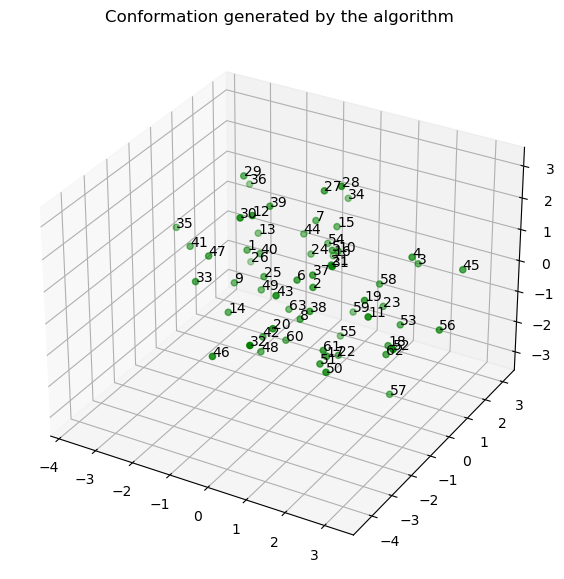

In [52]:
fig = plt.figure(figsize = (10,7))

ax = plt.axes(projection ="3d")

ax.scatter3D(xo, yo, zo, color = "green")
plt.title("Conformation generated by the algorithm")

for x,y,z,label in zip(xo,yo,zo,range(1,len(xo)+1)):
    ax.text(x,y,z,label)

#use this line if you want to save image
#plt.savefig('Conformation_generated_by_the_algorithm.png')

# show plot
plt.show()

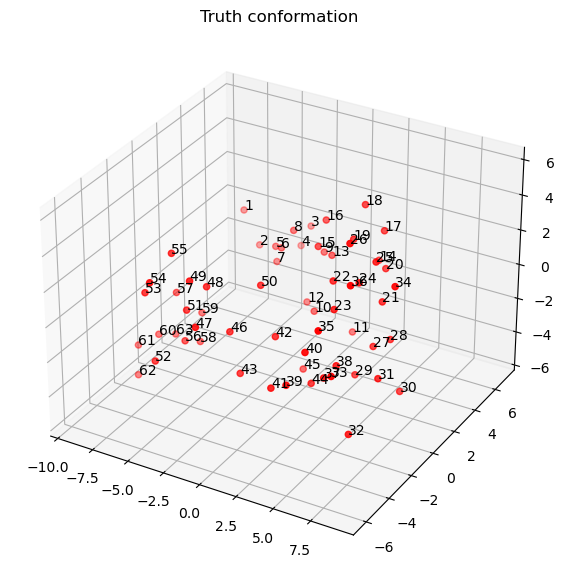

In [53]:
coor_a = np.stack(coor)

#create x,y,z coordinates for plot
xr = coor_a[:,0]
yr = coor_a[:, 1]
zr = coor_a[:, 2]

fig2 = plt.figure(figsize = (10,7))

ax = plt.axes(projection ="3d")

ax.scatter3D(xr, yr, zr, color = "red")
plt.title("Truth conformation")

for x,y,z,label in zip(xr,yr,zr,range(1,len(xr)+1)):
    ax.text(x,y,z,label)

#use this line if you want to save image    
#plt.savefig('truth_conformation.png')

# show plot
plt.show()

<a id="sec-5" name="sec-5"></a>
# 5. Augmented lagrangian method

reference: github of Burer and Monteiro
https://github.com/ChristophorusX/Burer-Monteiro/blob/master/burer_monteiro.py
We used some functions from the link.

<a id="sec-5-1" name="sec-5-1"></a>
### 5.1 Augmented lagrangian method

In [54]:
def augmented_C(n,E):
    m = len(E)
 
    row_ind,col_ind = [],[]
    data = [-1,-1,1,1] * len(E)
    
    for i,j in E: 
        row_ind += [i-1,j-1,i-1,j-1]
        col_ind += [i-1,j-1,j-1,i-1]
    
    data += [1] * (n*n)
    
    for i,j in itertools.product(range(n),range(n)):
        row_ind.append(i)
        col_ind.append(j)
        
    data += [2] * m
    
    for i in range(m):
        row_ind.append(n + i)
        col_ind.append(n + i)
  
    
    return csr_array((data,(row_ind,col_ind)),dtype = np.int8, shape = (n+2*m,n+2*m))

In [55]:
def augmented_A_i(n,E):
    augmented_A_i = []
    
    m = len(E)
    
    for k,(i,j) in enumerate(E):
        
        data = [1,1,-1,-1,-1,1] 
        
        row_ind = [i-1,j-1,i-1,j-1, n + k, n+m+k]
        col_ind = [i-1,j-1,j-1,i-1, n + k, n+m+k]
        
        augmented_A_i.append(csr_array((data,(row_ind,col_ind)),dtype = np.int8, shape = (n+2*m,n+2*m)))
        
    return augmented_A_i

In [56]:
def constraints2(n,E, delta, V):
    vec = np.zeros(len(delta))
    m = len(E)
    for k,(i,j) in enumerate(E):
        vec[k] = np.sum((V[i-1]-V[j-1])**2) - np.sum(V[n + k] **2) +np.sum(V[n+m+k]**2) - delta[k]    
    return vec

In [57]:
def constraints(A_i_list, delta, V):
    vec = np.zeros(len(delta))
    
    for i in range(len(delta)):
        vec[i] = np.trace(A_i_list[i].dot(V@V.T)) - delta[i]
    
    return vec

In [58]:
def vector_to_matrix(V, k):
    return V.reshape((-1, k))


def matrix_to_vector(R):
    
    u = R.reshape((1, -1)).ravel()
    return u

In [59]:
def augmented_lagrangian_func(R, v, penalty, n, m, k, E,delta,A_i_list,C):
    
    V = vector_to_matrix(R, k)
    
    #A_i_list = augmented_A_i(n,E)
    #C = augmented_C(n,E)    
    #vec = constraints(A_i_list, delta, V)
    
    vec = constraints2(n,E, delta, V)
    
   # c = np.trace(C.dot(V@V.T)) + v.dot(vec) + penalty/2 * vec@vec

    c = np.trace(V.T@(C@V)) + v.dot(vec) + penalty/2 * vec@vec
    
    return c

In [60]:
def jacobian(R, v, penalty, n, m, k, E,delta,A_i_list,C):
    V = vector_to_matrix(R, k)
    #C = augmented_C(n,E)
    
    #A_i_list = augmented_A_i(n,E)
    #vec = constraints(A_i_list, delta, V)
    vec = constraints2(n,E, delta, V)
    
    l1 = reduce(lambda x,y:x+y,[v[i]*A_i_list[i] for i in range(m)])
    l2 = reduce(lambda x,y:x+y,[vec[i]*A_i_list[i] for i in range(m)])
    
    
    jac = 2*C.dot(V) + 2*l1.dot(V) + 2*penalty*l2.dot(V)
    
    return matrix_to_vector(jac)

In [61]:
def augmented_lagrangian(n,E, delta,print_ite = True):
    
    m  = len(E)
    k = 3
    A_i_list = augmented_A_i(n,E)
    C = augmented_C(n,E)
    gamma = 10
    eta = 0.25
    v_0 = np.ones(m, dtype = np.int8)
    v_best = v_0
    sigma_0 = 1
    sigma_best = sigma_0

    #set up the intial point. Here we avoid using the all one matrix as it makes all points overlap
    R_0 = np.random.rand((n+2*m)*k)

    optimizer = opt.minimize(lambda R: augmented_lagrangian_func(R, v_0, sigma_0, n, m, k, E,delta,A_i_list,C),R_0, \
                   jac=lambda R: jacobian(R, v_0, sigma_0,n, m, k, E,delta,A_i_list,C), method="L-BFGS-B")
    V_0 = vector_to_matrix(optimizer.x, k)

    #vec2 = constraints(A_i_list, delta, V_0)
    vec2 = constraints2(n,E, delta, V_0)

    alpha_0 = vec2@vec2
    alpha_best = alpha_0
    ite = 0
    R_V = R_0
    #last_objective =  np.trace(C.dot(V_0@V_0.T))
    last_objective =  np.trace(V_0.T@(C@V_0))

    while True:
        optimizer = opt.minimize(lambda R: augmented_lagrangian_func(R, v_best, sigma_best, n, m, k, E,delta,A_i_list,C),R_V, \
                     jac=lambda R: jacobian(R, v_best, sigma_best,n, m, k, E,delta,A_i_list,C), method="L-BFGS-B")
        R_V = optimizer.x
        V = vector_to_matrix(R_V, k)
     #   vec2 = constraints(A_i_list, delta, V)
        vec2 = constraints2(n,E, delta, V)
        alpha = vec2@vec2
        if alpha < eta * alpha_best:
            v_best = v_best + sigma_best* vec2
            alpha_best = alpha
        else:
            sigma_best = gamma*sigma_best
    
        target_value = abs(np.trace(V.T@(C@V)) + v_best.dot(vec2))
        if target_value < 1:
            target_value = 1
        
        metric = abs(np.trace(V.T@(C@V)) + v_best.dot(vec2) + sigma_best/2 * np.sum(vec2@vec2) - last_objective) / target_value
        if print_ite == True:
            print("The iteration is {} with value {}\n".format(ite,metric))
        if metric  < 1e-4:
            break
        
        last_objective = np.trace(V.T@(C@V))
    
        ite += 1
        
    return V
    
    

In [62]:
n,E, delta = artificially_generated(4, 2.5)
m = len(E)
start = timeit.default_timer() 

V = augmented_lagrangian(n,E, delta)


stop = timeit.default_timer()
print("The time use for (n,|E|) = ({},{}) is {}\n".format(n,m, stop - start))

V_2 = V[0:n,]
print("The error is {}\n".format(error_LV(V_2, E, delta)))
print("The maximum violations of rotation is {}\n".format(max_violations(E,V_2,delta)))

The iteration is 0 with value 0.38819528834718575

The iteration is 1 with value 0.07845366935978194

The iteration is 2 with value 0.004734765220214485

The iteration is 3 with value 1.8719409274837387e-05

The time use for (n,|E|) = (64,360) is 30.112510374980047

The error is 50.025917557046355

The maximum violations of rotation is 0.9998629438855194



<a id="sec-5-2" name="sec-5-2"></a>
### 5.2 Memory comparison

In [63]:
def watch(done,p,peak_box): 
    '''watch is a function that returns the peak of the memory used between the start and the end of the thread.
    p is the process we are in, done is the event/flag which tells us whether the main thread stops.
    peak_box records the peak of the memory used.'''
    while not done.is_set():
        r = p.memory_info().rss/1e6 #mb 
        if r > peak_box['peak']:
            peak_box['peak'] = r
        time.sleep(0.002) #sampling at 2ms

In [64]:
def peak_mb(fn):
    '''peak_mb returns the memory used by the function fn'''
    gc.collect()
    p = psutil.Process(os.getpid()) #p is the process we are in
    base = p.memory_info().rss/1e6 #the current memory used
    peak_box = {'peak':base} 
    
    done = threading.Event() #event/flag tells the following thread whether the main thread stops
    
    th = threading.Thread(target = watch, args = (done, p, peak_box ), daemon = True)
    th.start()
    
    try:
        out = fn()  #run the function, and assign its value to a variable
    finally:
        done.set() #set the event to be true
        th.join() #wait until watch finishes 
        
    return out, peak_box['peak'] - base

In [65]:
for l in [4,5]: 
    n,E, delta = artificially_generated(l, 2.5)
    m = len(E)
    _, phase1_mem = peak_mb(lambda: phase1(n,E,delta))
    print('For case ({},{}), the memory required for phase1(SDP) is {} MB \n'.format(n,m,phase1_mem))
    _, AL_mem = peak_mb(lambda: augmented_lagrangian(n,E,delta,print_ite = False))
    print('For case ({},{}), the memory required for augemnted lagrangain method is {} MB \n'.format(n,m,AL_mem))
    

For case (64,360), the memory required for phase1(SDP) is 38.46963200000005 MB 

For case (64,360), the memory required for augemnted lagrangain method is 2.179072000000019 MB 

For case (125,780), the memory required for phase1(SDP) is 433.668096 MB 

For case (125,780), the memory required for augemnted lagrangain method is 48.00512000000003 MB 

